# Example: cord blood LARRY data from CLADES

The cord blood LARRY experiment (HDBI58; days 3, 10 and 17) published with CLADES (Gao, Barile et al., Nat Commun
2025). CLADES grouped its clones into 12 meta-clones. This notebook tests clomet on these published data and compares
its meta-clones with the CLADES ones:

1. the clone x timepoint_celltype matrix, rebuilt as in CLADES (`demo/CordBlood_Refine/prepare_input.ipynb`),
2. a check that the rebuilt matrix gives back the CLADES meta-clones with their own clustering,
3. clomet on the same matrix: the Leiden scan, the diagnostics for choosing k, and the comparison with the CLADES
   meta-clones.

Data needed (from the CLADES authors): `adata_cord_blood_as_submitted.h5ad` (only its cell metadata is read) and
`CordBlood_Obs_Clones.pkl`. Set `CLOMET_CB_DIR` to the folder that holds them.

In [1]:
import os
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.io as pio
from sklearn.metrics import adjusted_rand_score

import clomet

warnings.filterwarnings('ignore')
sc.set_figure_params(scanpy=False, dpi=100)
data_dir = Path(os.environ.get('CLOMET_CB_DIR', '.'))

## 1. The clone matrix

GFP+ cells with a barcode; cells per clone and timepoint_celltype; clones with at least 3 cells.

In [2]:
obs = ad.read_h5ad(data_dir / 'adata_cord_blood_as_submitted.h5ad', backed='r').obs.copy()
data = pd.read_pickle(data_dir / 'CordBlood_Obs_Clones.pkl')
barcodes = data[data.columns[14:]].fillna(0).loc[obs.index]

pos = obs[(obs.GFP == 'GFP+') & (obs.clones.astype(str) != 'Clone_')]
mat = barcodes.loc[pos.index].assign(time_label_full=pos.time_label_full.astype(str))
mat = mat.groupby('time_label_full').sum().T
mat = mat[mat.sum(axis=1) >= 3]
counts = mat.loc[:, mat.sum() > 0]

published = (obs.loc[obs['Meta clones'].astype(str) != '-1.0'].groupby('clones', observed=True)['Meta clones']
             .first().astype(str).reindex(counts.index).rename('published'))
print(f'{counts.shape[0]} clones x {counts.shape[1]} timepoint_celltype columns; '
      f'{published.notna().sum()} clones with a published meta-clone ({published.nunique()} meta-clones)')
counts.iloc[:5, :8]

606 clones x 31 timepoint_celltype columns; 606 clones with a published meta-clone (12 meta-clones)


time_label_full,Day10_DC,Day10_DC precursor,Day10_Early Erythroid,Day10_HSC/MPP 1,Day10_HSC/MPP 2,Day10_Late Erythroid,Day10_MEMP,Day10_Mast cell
Clone_1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Clone_3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
Clone_6,0.0,0.0,2.0,0.0,0.0,1.0,0.0,0.0
Clone_12,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0
Clone_13,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 2. Check: the CLADES clustering, re-run

PCA, 15 neighbours, Leiden at resolution 1, on the raw counts, as in CLADES.

In [3]:
def single_leiden(x, seed=0, metric='euclidean', n_neighbors=15, n_pcs=30, resolution=1):
    m = sc.AnnData(x.values.astype(np.float32))
    sc.tl.pca(m, n_comps=n_pcs, random_state=seed)
    sc.pp.neighbors(m, n_neighbors=n_neighbors, metric=metric, random_state=seed)
    sc.tl.leiden(m, resolution=resolution, random_state=seed, flavor='leidenalg')
    return pd.Series(m.obs.leiden.values, index=x.index)


rerun = single_leiden(counts)
print(f'{rerun.nunique()} clusters; adjusted Rand index to the published meta-clones: '
      f'{adjusted_rand_score(published, rerun):.3f}')

12 clusters; adjusted Rand index to the published meta-clones: 0.865


## 3. clomet

Same input as CLADES: raw counts (`log1p=False`), Euclidean distance, 15 neighbours, 30 principal components (the
matrix has 31 columns). The Leiden scan, then the diagnostics for choosing k.

30 resolutions, 15 partitions used (k = [5, 8, 9, 11, 12, 13, 14, 15, 16, 18, 19, 22, 23, 24, 25])


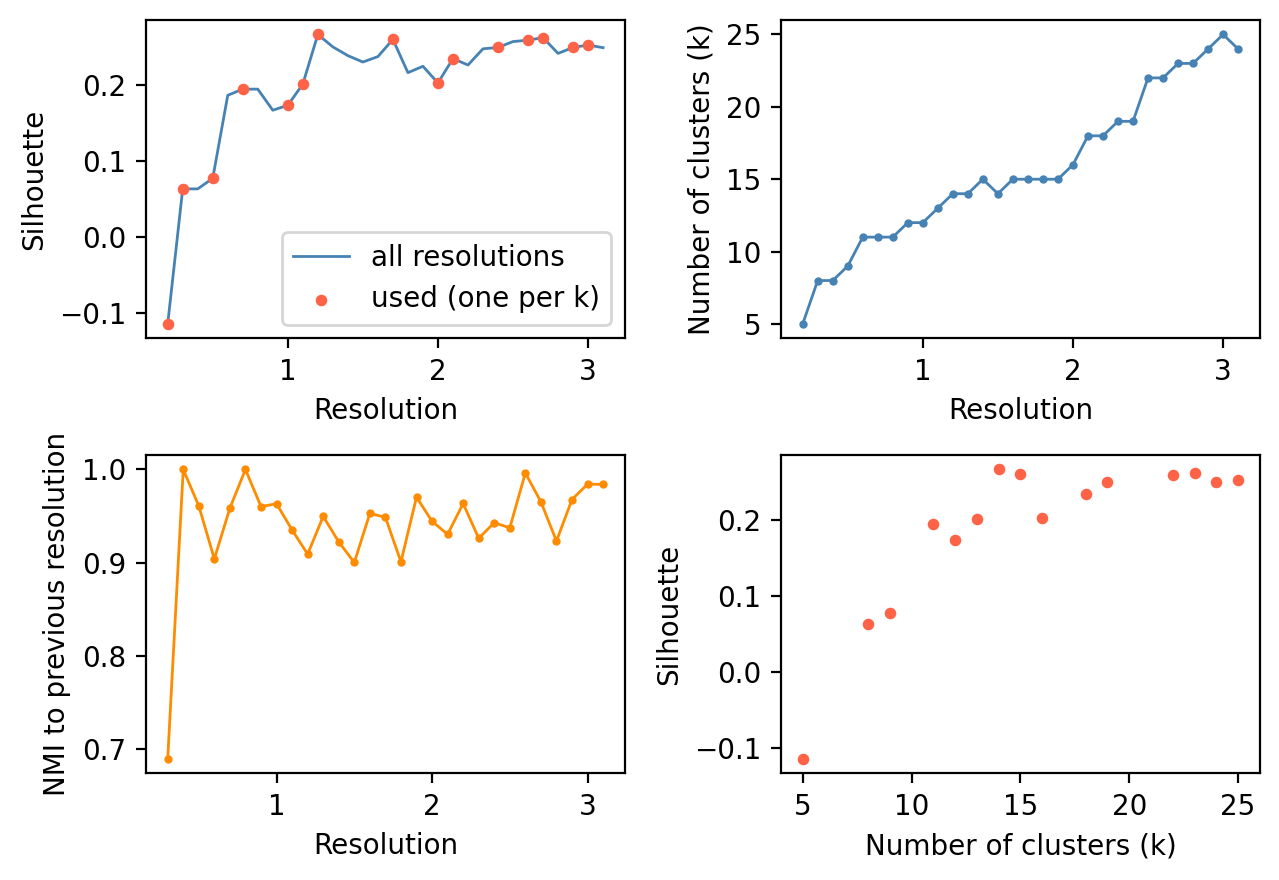

In [4]:
res = clomet.assign(counts, k=12, k_range=range(4, 21, 2), log1p=False, metric='euclidean', n_neighbors=15, n_pcs=30)
print(f'{len(res.scan)} resolutions, {len(res.used)} partitions used (k = {res.used.k.tolist()})')
clomet.pl.resolution_scan(res.scan, res.used)
plt.show()

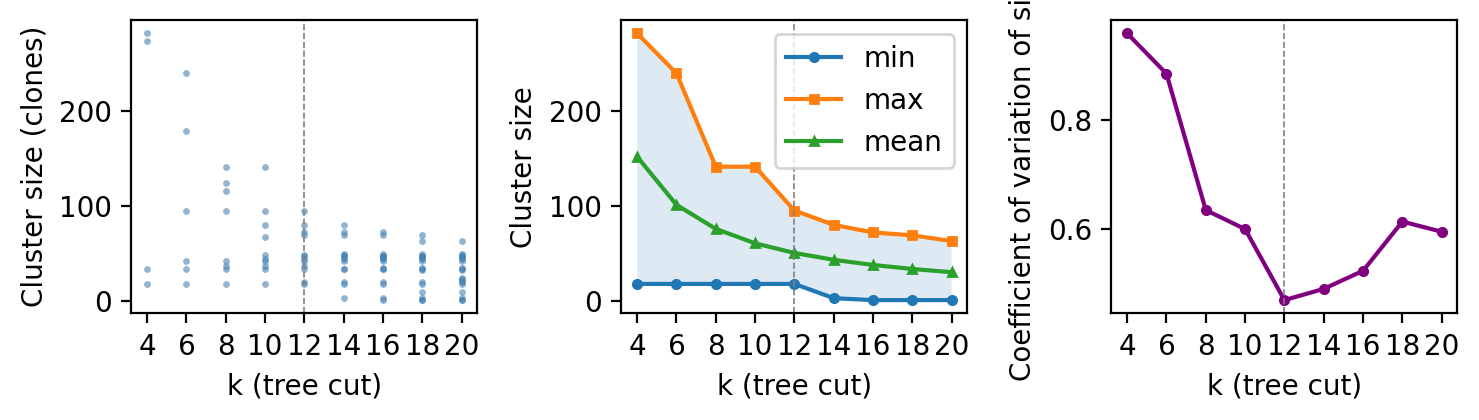

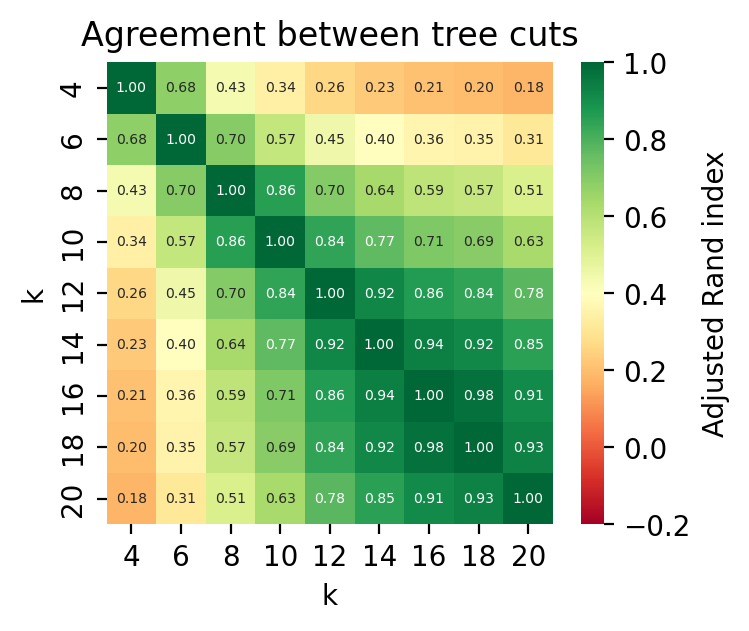

,k,n_clusters,min_size,max_size,mean_size,cv_size
0,4,4,18,281,151.500000,0.957748
1,6,6,18,239,101.000000,0.884109
2,8,8,18,141,75.750000,0.635380
3,10,10,18,141,60.600000,0.600654
4,12,12,18,95,50.500000,0.471218
5,14,14,3,80,43.285714,0.491699
6,16,16,1,72,37.875000,0.524687
7,18,18,1,69,33.666667,0.614415
8,20,20,1,63,30.300000,0.595900


In [5]:
clomet.pl.choose_k(res.cuts, res.k_summary, res.k_range, chosen=12)
plt.show()
clomet.pl.cut_ari(res.ari)
plt.show()
res.k_summary

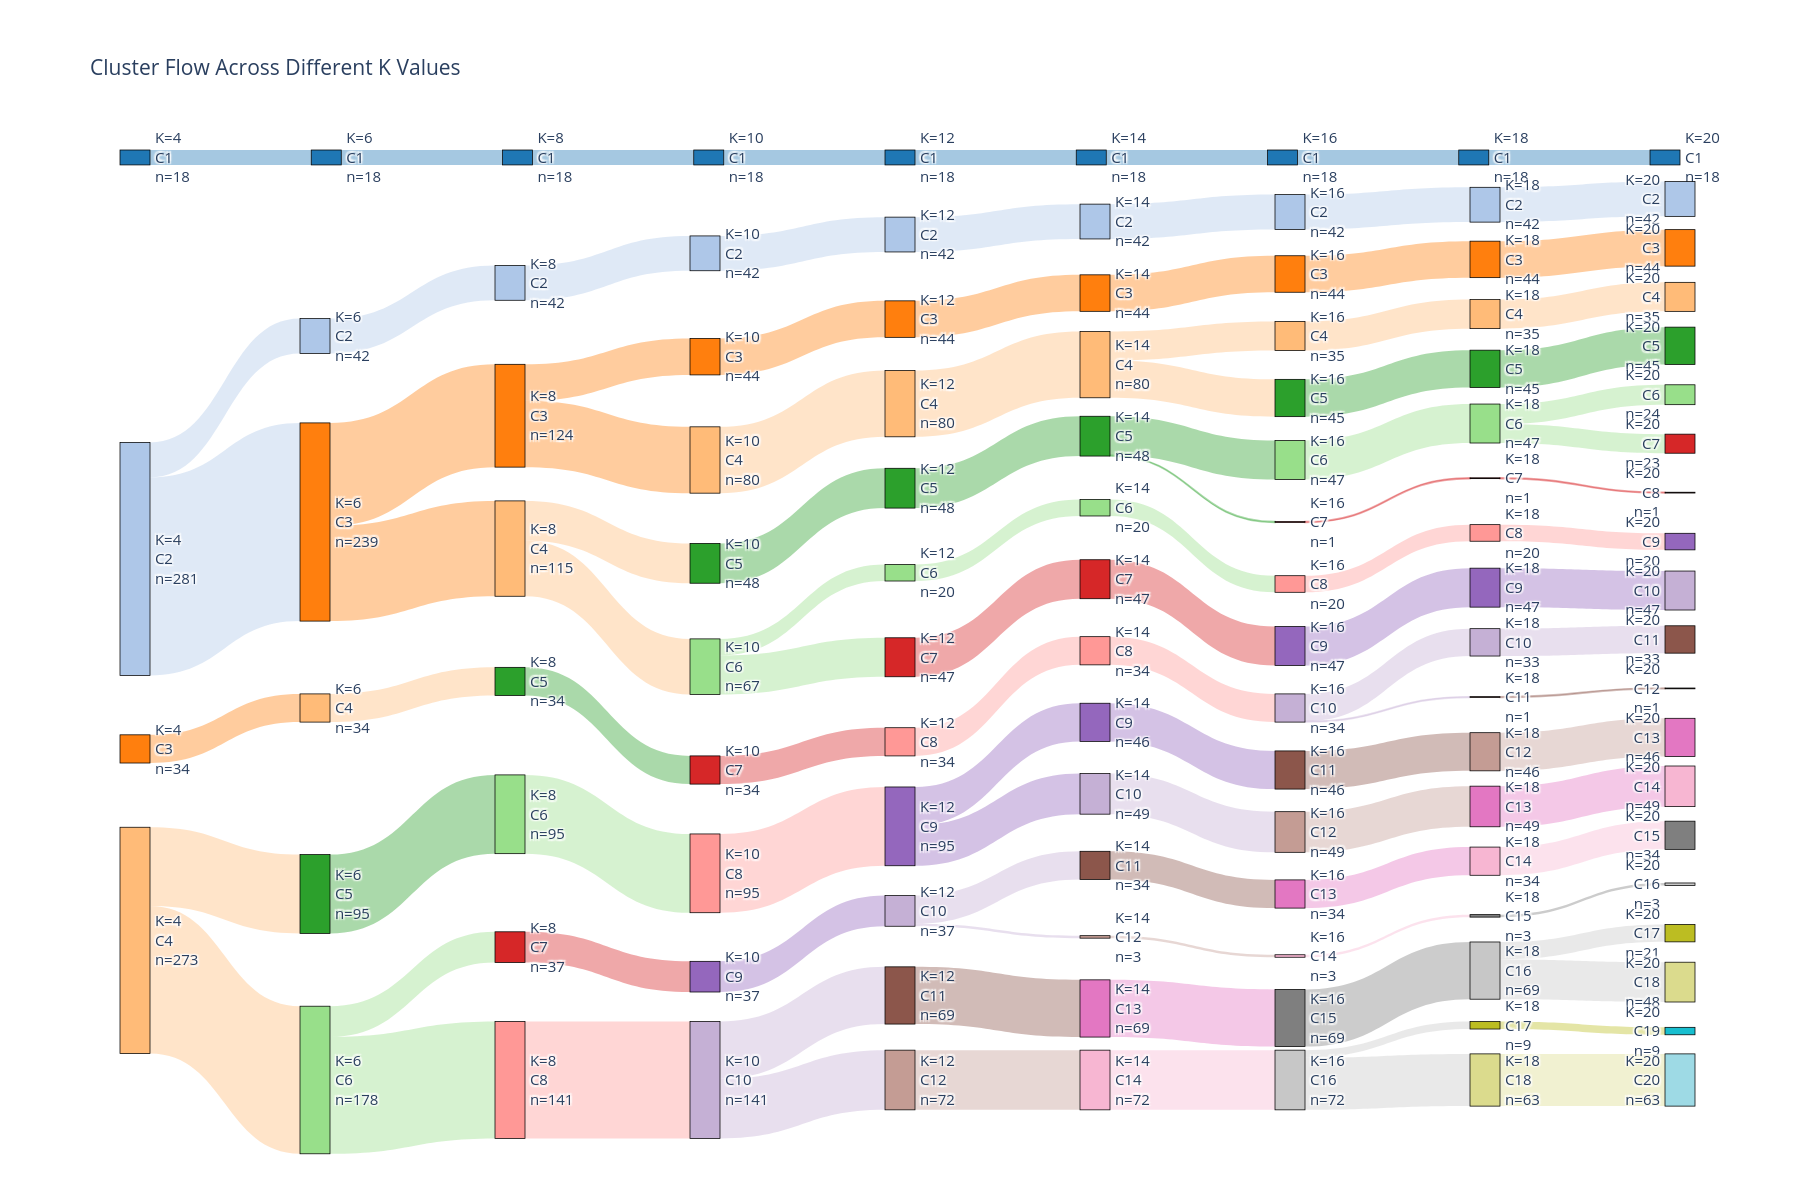

In [6]:
pio.renderers['png'].scale = 1.5
clomet.pl.sankey(res.cuts, res.k_range).show(renderer='png')

## 4. clomet against the CLADES meta-clones

The tree cut at k = 12 (the number of CLADES meta-clones). Rows: CLADES meta-clones; columns: clomet meta-clones.

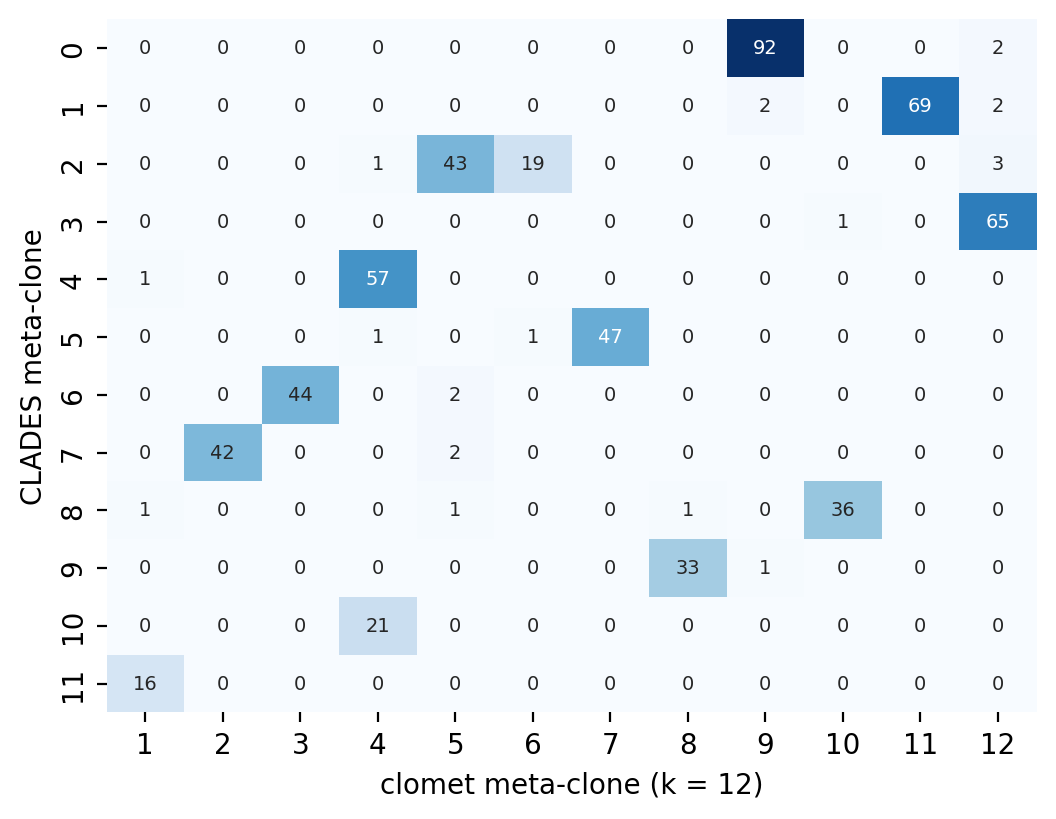

adjusted Rand index, clomet vs CLADES meta-clones: 0.860


,clones,share in the main clomet meta-clone
published,,
0,94,0.98
1,73,0.95
2,66,0.65
3,66,0.98
4,58,0.98
5,49,0.96
6,46,0.96
7,44,0.95
8,39,0.92


In [7]:
tab = pd.crosstab(published, res.clusters)
tab = tab.loc[sorted(tab.index, key=int)]
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(tab, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws=dict(fontsize=7))
ax.set_xlabel('clomet meta-clone (k = 12)'); ax.set_ylabel('CLADES meta-clone')
plt.show()
print(f'adjusted Rand index, clomet vs CLADES meta-clones: {adjusted_rand_score(published, res.clusters):.3f}')
best = tab.div(tab.sum(axis=1), axis=0).max(axis=1).rename('share in the main clomet meta-clone')
pd.concat([tab.sum(axis=1).rename('clones'), best.round(2)], axis=1)

## Result

- The rebuilt matrix matches CLADES: 606 clones x 31 columns, all with a CLADES meta-clone; their own clustering, re-run
  on it, gives back the CLADES meta-clones (adjusted Rand index 0.865).
- clomet's tree cut at k = 12 agrees with the CLADES meta-clones (adjusted Rand index 0.86). In 11 of the 12 CLADES
  meta-clones, 92-100 % of the clones fall in one clomet meta-clone; CLADES meta-clone 2 is divided (65 % in its main
  clomet meta-clone).
- The cluster sizes point to the same number: the smallest cluster stays at 18 clones up to k = 12 and drops to 3
  clones at k = 14.